[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


Classifier: MultinomialNB
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.87      1980
           1       0.86      0.89      0.87      2020

    accuracy                           0.87      4000
   macro avg       0.87      0.87      0.87      4000
weighted avg       0.87      0.87      0.87      4000

Confusion Matrix:
[[1684  296]
 [ 224 1796]]
F1 Score: 0.8735
Recall Score: 0.8891
Accuracy: 0.8700
Precision Score: 0.8585


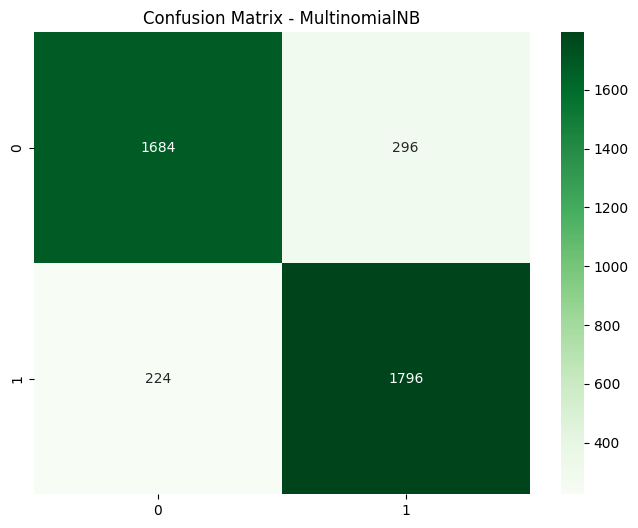

Classifier: LogisticRegression
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.86      0.86      1980
           1       0.86      0.87      0.87      2020

    accuracy                           0.87      4000
   macro avg       0.87      0.87      0.87      4000
weighted avg       0.87      0.87      0.87      4000

Confusion Matrix:
[[1704  276]
 [ 260 1760]]
F1 Score: 0.8679
Recall Score: 0.8713
Accuracy: 0.8660
Precision Score: 0.8644


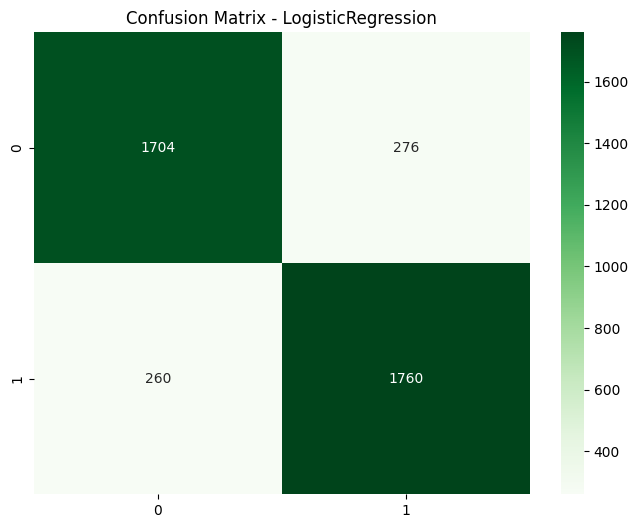

Classifier: DecisionTreeClassifier
Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.72      0.75      1980
           1       0.75      0.82      0.78      2020

    accuracy                           0.77      4000
   macro avg       0.77      0.77      0.77      4000
weighted avg       0.77      0.77      0.77      4000

Confusion Matrix:
[[1422  558]
 [ 372 1648]]
F1 Score: 0.7799
Recall Score: 0.8158
Accuracy: 0.7675
Precision Score: 0.7471


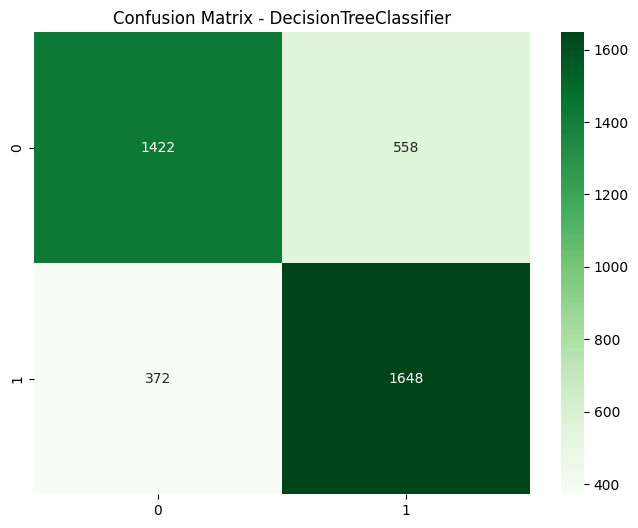

Classifier: RandomForestClassifier
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.79      0.82      1980
           1       0.81      0.86      0.83      2020

    accuracy                           0.83      4000
   macro avg       0.83      0.83      0.83      4000
weighted avg       0.83      0.83      0.83      4000

Confusion Matrix:
[[1568  412]
 [ 283 1737]]
F1 Score: 0.8333
Recall Score: 0.8599
Accuracy: 0.8263
Precision Score: 0.8083


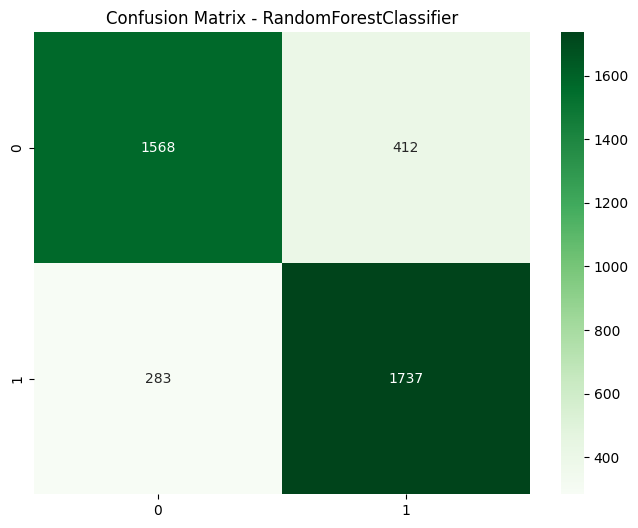

Classifier: GradientBoostingClassifier
Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.85      0.77      1980
           1       0.81      0.66      0.73      2020

    accuracy                           0.75      4000
   macro avg       0.76      0.75      0.75      4000
weighted avg       0.76      0.75      0.75      4000

Confusion Matrix:
[[1674  306]
 [ 680 1340]]
F1 Score: 0.7310
Recall Score: 0.6634
Accuracy: 0.7535
Precision Score: 0.8141


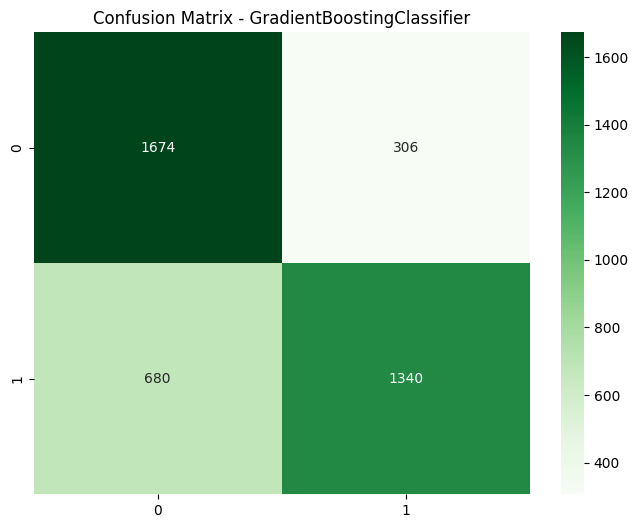

Classifier: SVC
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.87      0.87      1980
           1       0.87      0.88      0.87      2020

    accuracy                           0.87      4000
   macro avg       0.87      0.87      0.87      4000
weighted avg       0.87      0.87      0.87      4000

Confusion Matrix:
[[1720  260]
 [ 250 1770]]
F1 Score: 0.8741
Recall Score: 0.8762
Accuracy: 0.8725
Precision Score: 0.8719


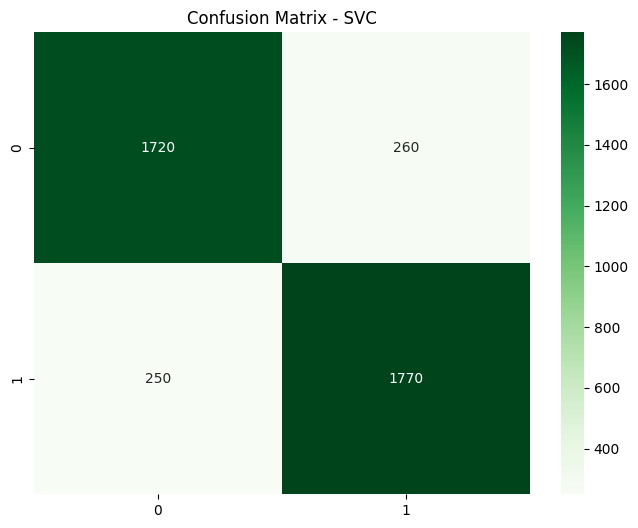

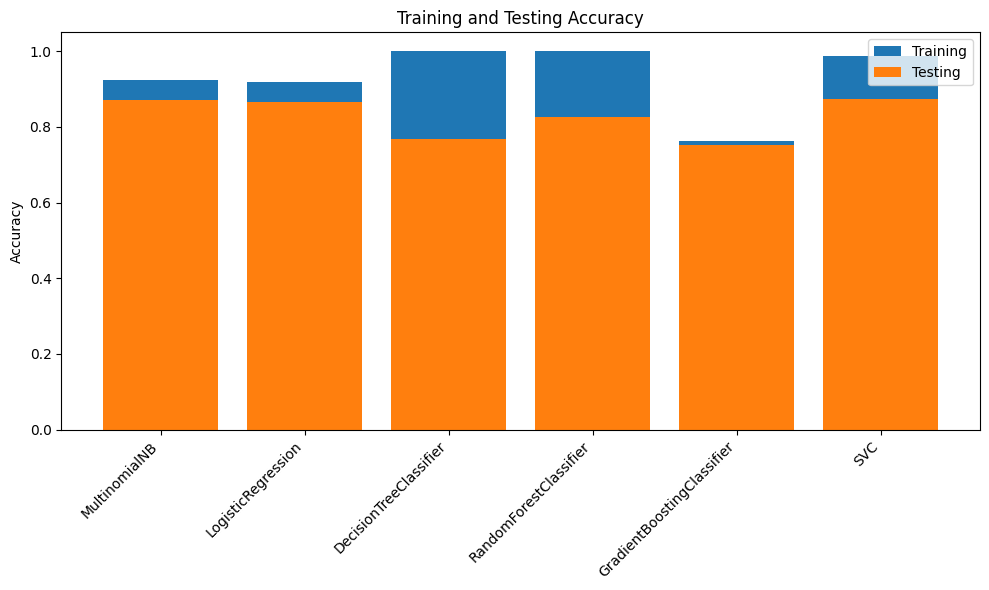

Best Classifier in terms of Accuracy: SVC


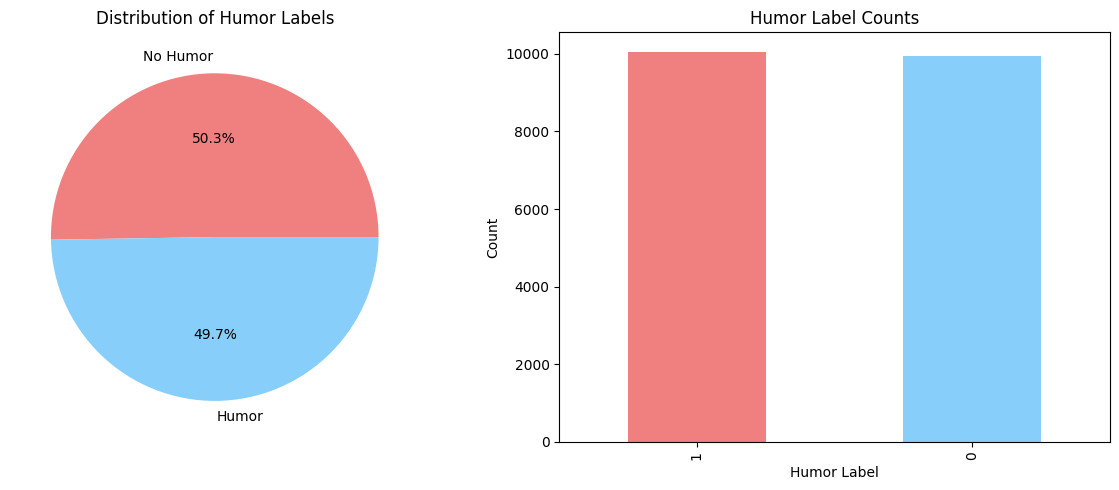

In [4]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, accuracy_score, precision_score
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import make_pipeline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (replace 'dataset.csv' with your file path)
dataset = pd.read_csv('/content/sample_data/processed_data(20k).csv')

# Drop rows with missing values
dataset = dataset.dropna()

# Preprocessing: Assuming 'text' column contains text data and 'humour' column contains labels
X = dataset['text']
y = dataset['humour']

# Preprocessing steps
nltk.download('stopwords')
nltk.download('wordnet')
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+', '', text)

    # Remove special characters and punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Tokenize and remove stopwords
    tokens = [word for word in text.split() if word not in stop_words]

    # Apply stemming and lemmatization
    stemmed_tokens = [stemmer.stem(token) for token in tokens]
    lemmatized_tokens = [lemmatizer.lemmatize(token) for token in stemmed_tokens]

    # Join tokens back to text
    processed_text = ' '.join(lemmatized_tokens)

    return processed_text

# Apply preprocessing to X
X = X.apply(preprocess_text)

# Label encoding for the target variable
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

# Create a TF-IDF vectorizer
vectorizer = TfidfVectorizer()

# Transform text data to TF-IDF features
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Define classifiers
classifiers = [
    MultinomialNB(),
    LogisticRegression(),
    DecisionTreeClassifier(),
    RandomForestClassifier(),
    GradientBoostingClassifier(),
    SVC()
]

# Train and evaluate classifiers
best_classifier = None
best_accuracy = 0

for classifier in classifiers:
    try:
        model = make_pipeline(classifier)
        model.fit(X_train_tfidf, y_train)

        y_pred = model.predict(X_test_tfidf)

        # Evaluate the classifier
        f1 = f1_score(y_test, y_pred)
        recall = recall_score(y_test, y_pred)
        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(y_test, y_pred)

        print(f"Classifier: {classifier.__class__.__name__}")
        print("Classification Report:")
        print(classification_report(y_test, y_pred))
        print("Confusion Matrix:")
        confusion = confusion_matrix(y_test, y_pred)
        print(confusion)
        print(f"F1 Score: {f1:.4f}")
        print(f"Recall Score: {recall:.4f}")
        print(f"Accuracy: {accuracy:.4f}")
        print(f"Precision Score: {precision:.4f}")
        print("="*50)

        # Update best classifier
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            best_classifier = classifier.__class__.__name__

        # Plot confusion matrix
        plt.figure(figsize=(8, 6))
        sns.heatmap(confusion, annot=True, fmt="d", cmap="Greens")  # Set cmap to Greens
        plt.title(f"Confusion Matrix - {classifier.__class__.__name__}")
        plt.show()

    except Exception as e:
        print(f"Error occurred for classifier {classifier.__class__.__name__}: {e}")

# Training and testing accuracy graph
training_scores = [clf.score(X_train_tfidf, y_train) for clf in classifiers]
testing_scores = [clf.score(X_test_tfidf, y_test) for clf in classifiers]

plt.figure(figsize=(10, 6))
plt.bar([clf.__class__.__name__ for clf in classifiers], training_scores, label='Training')
plt.bar([clf.__class__.__name__ for clf in classifiers], testing_scores, label='Testing')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

# Display best classifier
print(f"Best Classifier in terms of Accuracy: {best_classifier}")

# Visualization: Pie chart and bar graph for humor and no humor
humor_counts = dataset['humour'].value_counts()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.pie(humor_counts, labels=['No Humor', 'Humor'], autopct='%1.1f%%', colors=['lightcoral', 'lightskyblue'])
plt.title('Distribution of Humor Labels')

plt.subplot(1, 2, 2)
humor_counts.plot(kind='bar', color=['lightcoral', 'lightskyblue'])
plt.xlabel('Humor Label')
plt.ylabel('Count')
plt.title('Humor Label Counts')

plt.tight_layout()
plt.show()
